In [1]:
import matplotlib.pyplot as plt
import torch
import torchvision
import os

from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from torchinfo import summary

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

In [3]:
device

device(type='mps')

In [4]:
def to_rgb(img):
    return img.convert('RGB')

In [5]:
IMG_SIZE = 224
seed = 42

train_tf = transforms.Compose([
    transforms.Lambda(to_rgb),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15), ratio=(0.3, 3.3), value="random")
])

test_tf = transforms.Compose([
    transforms.Lambda(to_rgb),
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [6]:
from torch.utils.data import random_split
root = './data'
test_ratio = 0.2

In [7]:
# Aynı Caltech101 datasetini train ve test için farklı transformlarla oluştur
ds_train_full = datasets.Caltech101(root=root, download=True, transform=train_tf)
ds_test_full  = datasets.Caltech101(root=root, download=True, transform=test_tf)

# Toplam veri sayısını ve train/test miktarlarını hesapla
n_total = len(ds_train_full)
n_test = int(n_total * test_ratio)
n_train = n_total - n_test

print(f'total: {n_total}')
print(f'train: {n_train}')
print(f'test:  {n_test}')

# Dataset indexlerini aynı seed ile reproducible şekilde karıştır
g = torch.Generator().manual_seed(seed)
perm = torch.randperm(n_total, generator=g).tolist()

# Karıştırılmış indexleri train ve test olarak ayır
train_idx = perm[:n_train]
test_idx = perm[n_train:]

# İlgili indexleri kullanarak train ve test subsetlerini oluştur
train_ds = Subset(ds_train_full, train_idx)
test_ds  = Subset(ds_test_full, test_idx)

# Train ve test datasetlerinin boyutlarını kontrol et
len(train_ds), len(test_ds)

total: 8677
train: 6942
test:  1735


(6942, 1735)

In [8]:
BATCH_SIZE = 32

train_dataloader = DataLoader(dataset=train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(dataset=test_ds, batch_size=BATCH_SIZE, shuffle=False)

In [9]:
print(ds_train_full.categories)

['Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octopus', 'okapi', 'pagoda', 'panda', 'pigeon', 'pizza', 'platypus', 'pyramid', 'revolver', 'rhino', 'rooster', 'saxophone', 'schooner', 'scissors', 'scorpion', 'sea_horse', 'snoopy', 'soccer_ball', 'stapler

In [10]:
len(ds_train_full.categories)

101

In [11]:
img, label = ds_train_full[4]

In [12]:
label

0

In [13]:
ds_train_full.categories[label]

'Faces'

In [14]:
class_names = ds_train_full.categories

In [15]:
print(class_names)

['Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octopus', 'okapi', 'pagoda', 'panda', 'pigeon', 'pizza', 'platypus', 'pyramid', 'revolver', 'rhino', 'rooster', 'saxophone', 'schooner', 'scissors', 'scorpion', 'sea_horse', 'snoopy', 'soccer_ball', 'stapler

In [16]:
height = 224
width = 224
color_channels = 3
patch_size = 16
number_of_patches = int((height*width) / (patch_size**2)) # 196

In [17]:
number_of_patches

196

In [18]:
embedding_layer_input_shape = (height,width,color_channels)
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)
print(embedding_layer_input_shape)
print(embedding_layer_output_shape)

(224, 224, 3)
(196, 768)


In [19]:
224 * 224 * 3 == 196 * 16 * 16 * 3

True

In [20]:
image, label = test_dataloader.dataset[133]
class_names[label]

'Motorbikes'

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


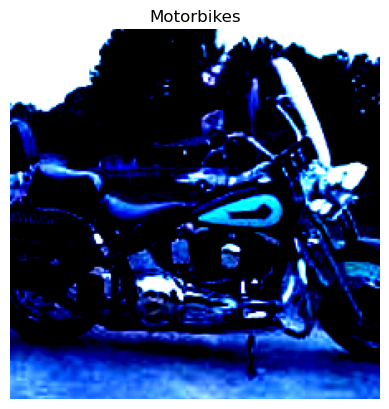

In [21]:
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False);

In [22]:
# image_permuted = image.permute(1, 2, 0).clamp(0,1)
# img_size = 224
# patch_size = 16
# num_patches = img_size/patch_size
# assert img_size % patch_size == 0, "Image size must be divisible by patch size"
# print(f"Number of patches per row: {num_patches}\
#         \nNumber of patches per column: {num_patches}\
#         \nTotal patches: {num_patches*num_patches}\
#         \nPatch size: {patch_size} pixels x {patch_size} pixels")

# # Create a series of subplots
# fig, axs = plt.subplots(nrows=img_size // patch_size, # need int not float
#                         ncols=img_size // patch_size,
#                         figsize=(num_patches, num_patches),
#                         sharex=True,
#                         sharey=True)

# # Loop through height and width of image
# for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
#     for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width

#         # Plot the permuted image patch (image_permuted -> (Height, Width, Color Channels))
#         axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # iterate through height
#                                         patch_width:patch_width+patch_size, # iterate through width
#                                         :]) # get all color channels

#         # Set up label information, remove the ticks for clarity and set labels to outside
#         axs[i, j].set_ylabel(i+1,
#                              rotation="horizontal",
#                              horizontalalignment="right",
#                              verticalalignment="center")
#         axs[i, j].set_xlabel(j+1)
#         axs[i, j].set_xticks([])
#         axs[i, j].set_yticks([])
#         axs[i, j].label_outer()

# # Set a super title
# fig.suptitle(f"{class_names[label]} -> Patchified", fontsize=16)
# plt.show()

# patch embedding

In [24]:
patch_size = 16
conv2d = nn.Conv2d(in_channels=3,
    out_channels=768,
    kernel_size=patch_size,
    stride=patch_size,
    padding=0)

In [25]:
print(image.unsqueeze(0).shape)
image_out_of_conv = conv2d(image.unsqueeze(0))
print(image_out_of_conv.shape)

torch.Size([1, 3, 224, 224])
torch.Size([1, 768, 14, 14])


In [26]:
flatten = nn.Flatten(start_dim=2,end_dim=-1)

In [27]:
image_out_of_conv_flattened = flatten(image_out_of_conv)

In [28]:
image_out_of_conv_flattened.shape

torch.Size([1, 768, 196])

In [29]:
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0,2,1)

In [30]:
image_out_of_conv_flattened_reshaped.shape

torch.Size([1, 196, 768])

In [31]:
class PatchEmbedding(nn.Module):
    def __init__(self,
                 in_channels:int = 3,
                 embedding_dim:int = 768,
                 patch_size:int = 16):
        super().__init__()

        self.patcher = nn.Conv2d(in_channels=in_channels,
                                 out_channels=embedding_dim,
                                 kernel_size=patch_size,
                                 stride=patch_size,
                                 padding=0)

        self.flatten = nn.Flatten(start_dim=2,end_dim=-1)
        
    def forward(self, x):
        
        image_resolution = x.shape[-1]
        assert image_resolution % patch_size == 0, f"Input image size must be divisible by patch size, image shape: {image_resolution}, patch size: {patch_size}"
        
        x_patched = self.patcher(x)
        x_flattened = self.flatten(x_patched)
        return x_flattened.permute(0,2,1)

In [32]:
patch_embedding = PatchEmbedding(in_channels=3,
                          patch_size=16,
                          embedding_dim=768)

patch_embedded_image = patch_embedding(image.unsqueeze(0))
print(image.unsqueeze(0).shape)
print(patch_embedded_image.shape)

torch.Size([1, 3, 224, 224])
torch.Size([1, 196, 768])


In [33]:
random_input_image = (1, 3, 224, 224)

summary(PatchEmbedding(),
         input_size=random_input_image, # try swapping this for "random_input_image_error"
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (patcher)                       [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

In [34]:
print(patch_embedding.patcher.weight.shape)

torch.Size([768, 3, 16, 16])


# Patch Embedding islemi bitti
## → patch'lere bölme
## → her patch'i embedding vektörüne dönüştürme
# ----------------------------------------------------------------------
 # CLASS TOKEN

In [36]:
print(patch_embedded_image)
print(f"Patch embedding shape: {patch_embedded_image.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[ 0.5818, -0.5274, -0.3192,  ..., -1.1787, -0.6600,  0.7797],
         [ 0.5757, -0.5127, -0.3179,  ..., -1.2004, -0.6750,  0.7707],
         [ 0.5551, -0.4771, -0.2908,  ..., -1.2218, -0.6689,  0.7615],
         ...,
         [ 0.3660, -0.3357, -0.2431,  ..., -0.4872, -0.2761,  0.2252],
         [ 0.4240, -0.3696, -0.2273,  ..., -0.4362, -0.2202,  0.1724],
         [ 0.3966, -0.2448, -0.2178,  ..., -0.4355, -0.2816,  0.2150]]],
       grad_fn=<PermuteBackward0>)
Patch embedding shape: torch.Size([1, 196, 768]) -> [batch_size, number_of_patches, embedding_dimension]


### Class token'ın da patch'lerle aynı embedding dimension'a sahip olması gerekiyor.

In [38]:
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]

class_token = nn.Parameter(torch.ones(batch_size,1,embedding_dimension),
                           requires_grad=True)

In [39]:
class_token[:,:,:10]

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)

In [40]:
class_token.shape

torch.Size([1, 1, 768])

In [41]:
patch_embedded_image.shape

torch.Size([1, 196, 768])

In [42]:
torch.cat((class_token, patch_embedded_image),dim=1) # cat yaparken birleştireceğin dimension dışında diğer bütün dimension’ların aynı olması gerekir.

tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [ 0.5818, -0.5274, -0.3192,  ..., -1.1787, -0.6600,  0.7797],
         [ 0.5757, -0.5127, -0.3179,  ..., -1.2004, -0.6750,  0.7707],
         ...,
         [ 0.3660, -0.3357, -0.2431,  ..., -0.4872, -0.2761,  0.2252],
         [ 0.4240, -0.3696, -0.2273,  ..., -0.4362, -0.2202,  0.1724],
         [ 0.3966, -0.2448, -0.2178,  ..., -0.4355, -0.2816,  0.2150]]],
       grad_fn=<CatBackward0>)

In [43]:
patch_embedded_image_with_class_embedding = torch.cat((class_token, patch_embedded_image),dim=1)

In [44]:
patch_embedded_image_with_class_embedding.shape

torch.Size([1, 197, 768])

# POSITION EMBEDDING

In [46]:
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [ 0.5818, -0.5274, -0.3192,  ..., -1.1787, -0.6600,  0.7797],
          [ 0.5757, -0.5127, -0.3179,  ..., -1.2004, -0.6750,  0.7707],
          ...,
          [ 0.3660, -0.3357, -0.2431,  ..., -0.4872, -0.2761,  0.2252],
          [ 0.4240, -0.3696, -0.2273,  ..., -0.4362, -0.2202,  0.1724],
          [ 0.3966, -0.2448, -0.2178,  ..., -0.4355, -0.2816,  0.2150]]],
        grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

In [47]:
number_of_patches = int((height*width) / (patch_size**2)) # 196
embedding_dimension = patch_embedded_image_with_class_embedding.shape[-1]

In [48]:
number_of_patches, embedding_dimension

(196, 768)

In [49]:
position_embedding = nn.Parameter(torch.ones(1,number_of_patches+1, embedding_dimension),requires_grad=True)

In [50]:
position_embedding.shape

torch.Size([1, 197, 768])

In [51]:
position_embedding[:, :10, :10]

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)

In [52]:
patch_class_position_embedding = patch_embedded_image_with_class_embedding + position_embedding

In [53]:
patch_class_position_embedding

tensor([[[ 2.0000,  2.0000,  2.0000,  ...,  2.0000,  2.0000,  2.0000],
         [ 1.5818,  0.4726,  0.6808,  ..., -0.1787,  0.3400,  1.7797],
         [ 1.5757,  0.4873,  0.6821,  ..., -0.2004,  0.3250,  1.7707],
         ...,
         [ 1.3660,  0.6643,  0.7569,  ...,  0.5128,  0.7239,  1.2252],
         [ 1.4240,  0.6304,  0.7727,  ...,  0.5638,  0.7798,  1.1724],
         [ 1.3966,  0.7552,  0.7822,  ...,  0.5645,  0.7184,  1.2150]]],
       grad_fn=<AddBackward0>)

In [54]:
patch_class_position_embedding.shape

torch.Size([1, 197, 768])

# patch embedding + class token + position embedding

In [56]:
# Patch boyutunu belirle ve image height/width değerlerini al
patch_size = 16
height, width = image.shape[1], image.shape[-1]
print(f'{image.shape}-> image tensor shape')

# Image tensoruna batch dimension ekle
x = image.unsqueeze(0)
print(f'{x.shape}-> image with batch dimension shape')

# Image'i patch'lere böl ve her patch'i embedding vektörüne dönüştür
patch_embedding_layer = PatchEmbedding(in_channels=3,embedding_dim=768,patch_size=patch_size)
patch_embeddings = patch_embedding_layer(x)
print(f'{patch_embeddings.shape}-> patching embedding shape')

# Batch size ve embedding dimension değerlerini al
batch_size = patch_embeddings.shape[0]
embedding_dimension = patch_embeddings.shape[-1]

# Learnable class token oluştur
class_token = nn.Parameter(torch.randn(batch_size, 1, embedding_dimension), requires_grad=True)
print(f'{class_token.shape}-> class token embedding shape')

# Class token'ı patch embeddinglerin başına ekle
patch_embeddings_with_class_token = torch.cat((class_token, patch_embeddings), dim = 1)
print(f'{patch_embeddings_with_class_token.shape}-> patch embeddings with class token shape')

# Toplam patch sayısını hesapla
number_of_patches = int((height * width) / patch_size**2)

# CLS token dahil her token için learnable position embedding oluştur
position_embedding = nn.Parameter(torch.randn(1, number_of_patches+1, embedding_dimension), requires_grad=True)

# Patch + CLS embeddinglerine position bilgisini ekle
patch_and_class_and_position_embedding = patch_embeddings_with_class_token + position_embedding
print(f'{patch_and_class_and_position_embedding.shape}-> patch and class token and position embedding shape')

torch.Size([3, 224, 224])-> image tensor shape
torch.Size([1, 3, 224, 224])-> image with batch dimension shape
torch.Size([1, 196, 768])-> patching embedding shape
torch.Size([1, 1, 768])-> class token embedding shape
torch.Size([1, 197, 768])-> patch embeddings with class token shape
torch.Size([1, 197, 768])-> patch and class token and position embedding shape


PatchEmbedding:
[B, 196, 768]

CLS eklendikten sonra:
[B, 197, 768]

Position embedding:
[1, 197, 768]

Toplama:
[B, 197, 768] + [1, 197, 768]
→ broadcasting
→ [B, 197, 768]

# [32,197,768] -> 32 image, image başına 197 token, token başına 768 feature

### [B, N, D]

#### B → Batch size - kaç image
#### N → Number of tokens - image başına kaç token
#### D → Dimension of each token embedding - token başına kaç feature // D = embedding dimension = hidden size

### [32, 197, 768]->
#### 32  → 32 image
#### 197 → image başına 197 token
#### 768 → her token 768 boyutlu embedding ile temsil ediliyor

# ------------------------------
# Multihead Self Attention (MSA)

In [61]:
class MultiheadSelfAttentionBlock(nn.Module):
    def __init__(self, 
                 embedding_dim:int = 768, # hidden size D
                 num_heads:int=12,
                 attn_dropout:float=0.0):
        super().__init__()

        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim) # feature lari normalize edicek

        self.multihead_attn = nn.MultiheadAttention(embed_dim=embedding_dim,
                                                    num_heads=num_heads,
                                                    dropout=attn_dropout,
                                                    batch_first=True)

    def forward(self, x):
        x = self.layer_norm(x)               #self-attention
        attn_output, _ = self.multihead_attn(query=x, # query embeddings
                                             key=x, # key embeddings
                                             value=x,# value embeddings
                                             need_weights=False)
        return attn_output

In [62]:
multihead_self_attention_block = MultiheadSelfAttentionBlock(embedding_dim=768, 
                                                             num_heads=12)

patched_image_through_msa_block = multihead_self_attention_block(patch_and_class_and_position_embedding)
print(f"Input shape of MSA block: {patch_and_class_and_position_embedding.shape}")
print(f"Output shape MSA block: {patched_image_through_msa_block.shape}")

Input shape of MSA block: torch.Size([1, 197, 768])
Output shape MSA block: torch.Size([1, 197, 768])


In [63]:
class MLPBlock(nn.Module):
    def __init__(self,
                embedding_dim:int=768,
                mlp_size:int=3072,
                mlp_dropout:float=0.1):
        super().__init__()

        self.layer_norm = nn.LayerNorm(normalized_shape=embedding_dim)

        self.mlp = nn.Sequential(
            nn.Linear(in_features=embedding_dim,
                     out_features=mlp_size),
            nn.GELU(),
            nn.Dropout(p=mlp_dropout),
            nn.Linear(in_features=mlp_size,
                     out_features=embedding_dim),
            nn.Dropout(p=mlp_dropout)
        )

    def forward(self, x):
        x = self.layer_norm(x)
        x = self.mlp(x)
        return x

In [64]:
mlp_block = MLPBlock(embedding_dim=768, # from Table 1
                     mlp_size=3072, # from Table 1
                     mlp_dropout=0.1)

patched_image_through_mlp_block = mlp_block(patched_image_through_msa_block)
print(f"Input shape of MLP block: {patched_image_through_msa_block.shape}")
print(f"Output shape MLP block: {patched_image_through_mlp_block.shape}")

Input shape of MLP block: torch.Size([1, 197, 768])
Output shape MLP block: torch.Size([1, 197, 768])


In [65]:
class TransformerEncoderBlock(nn.Module):
    def __init__(self,
                 embedding_dim: int = 768,
                 num_heads: int = 12,
                 attn_dropout: float = 0.0,
                 mlp_size: int = 3072,
                 mlp_dropout: float = 0.1,):
        super().__init__()

        self.msa_block = MultiheadSelfAttentionBlock(embedding_dim=embedding_dim,
                                                    num_heads=num_heads,
                                                    attn_dropout=attn_dropout)
        
        self.mlp_block = MLPBlock(embedding_dim=embedding_dim,
                                  mlp_size=mlp_size,
                                  mlp_dropout = mlp_dropout)

    def forward(self, x):
        x = self.msa_block(x) + x
        x = self.mlp_block(x) + x
        return x

In [66]:
transformer_encoder_block = TransformerEncoderBlock()

In [67]:
summary(model=transformer_encoder_block,
         input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderBlock (TransformerEncoderBlock)  [1, 197, 768]        [1, 197, 768]        --                   True
├─MultiheadSelfAttentionBlock (msa_block)          [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─MultiheadAttention (multihead_attn)         --                   [1, 197, 768]        2,362,368            True
├─MLPBlock (mlp_block)                             [1, 197, 768]        [1, 197, 768]        --                   True
│    └─LayerNorm (layer_norm)                      [1, 197, 768]        [1, 197, 768]        1,536                True
│    └─Sequential (mlp)                            [1, 197, 768]        [1, 197, 768]        --                   True
│    │    └─Linear (0)                     

In [68]:
torch_transformer_encoder_layer = nn.TransformerEncoderLayer(d_model=768, # Hidden size D from Table 1 for ViT-Base
                                                             nhead=12, # Heads from Table 1 for ViT-Base
                                                             dim_feedforward=3072, # MLP size from Table 1 for ViT-Base
                                                             dropout=0.1, # Amount of dropout for dense layers from Table 3 for ViT-Base
                                                             activation="gelu", # GELU non-linear activation
                                                             batch_first=True, # Do our batches come first?
                                                             norm_first=True)

In [69]:
torch_transformer_encoder_layer

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
  )
  (linear1): Linear(in_features=768, out_features=3072, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=3072, out_features=768, bias=True)
  (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

In [70]:
summary(model=torch_transformer_encoder_layer,
         input_size=(1, 197, 768), # (batch_size, num_patches, embedding_dimension)
         col_names=["input_size", "output_size", "num_params", "trainable"],
         col_width=20,
         row_settings=["var_names"])

Layer (type (var_name))                            Input Shape          Output Shape         Param #              Trainable
TransformerEncoderLayer (TransformerEncoderLayer)  [1, 197, 768]        [1, 197, 768]        --                   True
├─LayerNorm (norm1)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─MultiheadAttention (self_attn)                   [1, 197, 768]        [1, 197, 768]        2,362,368            True
├─Dropout (dropout1)                               [1, 197, 768]        [1, 197, 768]        --                   --
├─LayerNorm (norm2)                                [1, 197, 768]        [1, 197, 768]        1,536                True
├─Linear (linear1)                                 [1, 197, 768]        [1, 197, 3072]       2,362,368            True
├─Dropout (dropout)                                [1, 197, 3072]       [1, 197, 3072]       --                   --
├─Linear (linear2)                             

In [71]:
class ViT(nn.Module):
    def __init__(self,
                 embedding_dim: int = 768,
                 num_heads: int = 12,
                 attn_dropout: float = 0.0,
                 mlp_size: int = 3072,
                 mlp_dropout: float = 0.1,
                 embedding_dropout:float=0.1,
                 img_size:int=224,
                 in_channels:int=3,
                 patch_size:int=16,
                 num_transformer_layer:int=12,
                 num_classes:int=101
                ):
        super().__init__()

        self.num_patches = (img_size * img_size) // patch_size**2
        self.patch_embedding = PatchEmbedding(in_channels=in_channels,embedding_dim=embedding_dim, patch_size=patch_size)
        self.class_embedding = nn.Parameter(data = torch.ones(1,1,embedding_dim),requires_grad=True)
        self.position_embedding = nn.Parameter(data = torch.ones(1,self.num_patches+1, embedding_dim),requires_grad=True)
        self.embedding_dropout = nn.Dropout(p=embedding_dropout)
        self.transformer_encoder = nn.Sequential(* [TransformerEncoderBlock(embedding_dim=embedding_dim,
                                                                            num_heads=num_heads,
                                                                            attn_dropout=attn_dropout,
                                                                            mlp_size=mlp_size,
                                                                            mlp_dropout=mlp_dropout) for _ in range(num_transformer_layer)])
        self.classifier = nn.Sequential(
            nn.LayerNorm(normalized_shape=embedding_dim),
            nn.Linear(in_features=embedding_dim,
                     out_features=num_classes)
        )

    def forward(self, x):
    
            batch_size = x.shape[0]
            class_token = self.class_embedding.expand(batch_size, -1, -1)
            x = self.patch_embedding(x)
            x = torch.cat((class_token, x), dim=1)
            x = self.position_embedding + x
            x = self.embedding_dropout(x)
            x = self.transformer_encoder(x)
            x = self.classifier(x[:, 0]) 
    
            return x

In [72]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device):
    # Put model in train mode
    model.train()

    # Setup train loss and train accuracy values
    train_loss, train_acc = 0, 0

    # Loop through data loader data batches
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate  and accumulate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. Optimizer zero grad
        optimizer.zero_grad()

        # 4. Loss backward
        loss.backward()

        # 5. Optimizer step
        optimizer.step()

        # Calculate and accumulate accuracy metrics across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item() / len(y_pred)

    # Adjust metrics to get average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc


def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device):
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item() / len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc


def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          device: torch.device,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    # 2. Create empty results dictionary
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []
               }

    # 3. Loop through training and testing steps for a number of epochs
    for epoch in range(epochs):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer,
                                           device=device)
        test_loss, test_acc = test_step(model=model,
                                        dataloader=test_dataloader,
                                        loss_fn=loss_fn,
                                        device=device)

        # 4. Print out what's happening
        print(
            f"Epoch: {epoch + 1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

In [73]:
vit = ViT(num_classes=len(class_names)).to(device)

optimizer = torch.optim.Adam(params=vit.parameters(),
                             lr=3e-3)
loss_fn = torch.nn.CrossEntropyLoss()

results = train(model=vit,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=2,
                       device=device)

Epoch: 1 | train_loss: 4.5936 | train_acc: 0.0909 | test_loss: 4.3073 | test_acc: 0.0790
Epoch: 2 | train_loss: 4.2032 | train_acc: 0.1018 | test_loss: 4.1218 | test_acc: 0.1151
